<a href="https://colab.research.google.com/github/her-syntax/EDAB_Assignment-1/blob/main/EDAB2724_Assignment_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDAB2724: Bayesian Network, assignment 1

## 1. Install and import packages

In [ ]:
!pip -q install pgmpy openpyxl numpy pandas matplotlib seaborn scipy networkx

In [ ]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from google.colab import files
from scipy.stats import pearsonr

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import HillClimbSearch, MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 200)

print('Packages imported successfully.')


Packages imported successfully.


## 2. Upload the dataset

In [ ]:
uploaded = files.upload()

if not uploaded:
    raise RuntimeError('No dataset was uploaded.')

file_name = next(iter(uploaded))
print('Uploaded file:', file_name)

Saving Subsistence_Retail_Consumer_Data.csv to Subsistence_Retail_Consumer_Data.csv
Uploaded file: Subsistence_Retail_Consumer_Data.csv


In [ ]:
# Read the uploaded Excel workbook
xls = pd.ExcelFile(file_name)

print('Sheets in file:')
print(xls.sheet_names)

df = pd.read_excel(file_name, sheet_name=0)

print('\nDataset shape:', df.shape)

Sheets in file:
['Sheet1']

Dataset shape: (281, 41)


## 3. Understand the dataset

Before doing the Bayesian Network analysis, we first inspect the dataset.

We want to answer:
1. How many rows and columns are there?
2. What are the column names?
3. What data types are present?
4. Are there missing values?
5. Are there duplicated rows?
6. What do the selected variables look like?



In [ ]:
print('First 5 rows')
display(df.head())

First 5 rows


,Gender,Age,Marital Status,Employment Status,Level of Education,Regular Customer,Shopping frequency,E1,E2,E3,E4,C1,C2,C3,PS1,PS2,PS3,PE1,PE2,PE3,PE4,PE5,PE6,PPQ1,PPQ2,PPQ3,PPQ4,CT1,CT2,CT3,CT4,CT5,CT6,CT7,PV1,PV2,PV3,PI1,PI2,PI3,PI4
0,3,4,1,1,4,2,3,3,2,4,4,2,3,3,2,3,2,2,3,2,4,3,4,3,4,2,5,3,4,2,4,3,2,4,2,4,4,3,4,4,4
1,3,5,3,1,4,1,1,3,3,3,3,4,4,4,2,3,4,2,3,4,3,4,3,1,2,4,3,2,3,2,4,2,4,3,2,3,2,4,4,4,4
2,2,4,2,2,2,2,2,3,4,2,3,4,3,3,4,3,2,4,3,2,3,1,4,3,4,2,4,3,4,2,3,2,4,1,2,3,1,3,3,4,3
3,1,3,1,1,3,2,1,3,2,4,3,1,3,4,4,5,3,2,4,3,2,4,4,3,2,3,4,2,3,2,4,2,3,4,1,2,3,3,4,3,4
4,3,2,1,2,2,2,3,2,4,3,2,2,3,5,1,2,4,2,1,3,4,2,5,3,4,2,3,3,2,4,3,2,4,2,2,4,2,2,3,2,3


In [ ]:
print('Last 5 rows')
display(df.tail())

Last 5 rows


,Gender,Age,Marital Status,Employment Status,Level of Education,Regular Customer,Shopping frequency,E1,E2,E3,E4,C1,C2,C3,PS1,PS2,PS3,PE1,PE2,PE3,PE4,PE5,PE6,PPQ1,PPQ2,PPQ3,PPQ4,CT1,CT2,CT3,CT4,CT5,CT6,CT7,PV1,PV2,PV3,PI1,PI2,PI3,PI4
276,1,3,1,2,3,1,2,2,3,2,3,4,4,4,3,3,3,4,3,4,4,3,3,3,3,3,3,2,3,2,2,2,3,5,3,3,4,4,4,5,4
277,2,3,3,1,2,1,1,5,4,2,2,4,4,2,4,4,2,4,5,4,1,4,3,2,4,2,4,1,4,4,4,1,1,5,2,1,5,4,4,3,4
278,2,4,3,1,3,1,2,5,5,3,3,3,3,4,5,3,4,3,5,3,3,3,4,4,4,3,5,4,4,5,5,4,4,4,4,4,4,4,5,5,5
279,2,5,2,2,3,1,1,3,3,3,3,4,4,4,2,2,3,3,3,3,2,3,3,4,3,4,4,3,3,3,3,3,3,3,3,3,4,4,4,4,4
280,2,5,1,1,2,1,1,5,5,5,5,4,4,4,4,2,4,4,5,4,4,4,4,4,5,5,5,5,4,4,5,5,4,5,4,3,5,4,5,4,5


In [ ]:
print('Column names')
print(df.columns.tolist())

Column names
['Gender', 'Age', 'Marital Status', 'Employment Status', 'Level of Education', 'Regular Customer', 'Shopping frequency', 'E1', 'E2', 'E3', 'E4', 'C1', 'C2', 'C3', 'PS1', 'PS2', 'PS3', 'PE1', 'PE2', 'PE3', 'PE4', 'PE5', 'PE6', 'PPQ1', 'PPQ2', 'PPQ3', 'PPQ4', 'CT1', 'CT2', 'CT3', 'CT4', 'CT5', 'CT6', 'CT7', 'PV1', 'PV2', 'PV3', 'PI1', 'PI2', 'PI3', 'PI4']


In [ ]:
print('Data types')
print(df.dtypes)

Data types
Gender                int64
Age                   int64
Marital Status        int64
Employment Status     int64
Level of Education    int64
Regular Customer      int64
Shopping frequency    int64
E1                    int64
E2                    int64
E3                    int64
E4                    int64
C1                    int64
C2                    int64
C3                    int64
PS1                   int64
PS2                   int64
PS3                   int64
PE1                   int64
PE2                   int64
PE3                   int64
PE4                   int64
PE5                   int64
PE6                   int64
PPQ1                  int64
PPQ2                  int64
PPQ3                  int64
PPQ4                  int64
CT1                   int64
CT2                   int64
CT3                   int64
CT4                   int64
CT5                   int64
CT6                   int64
CT7                   int64
PV1                   int64
PV2      

In [ ]:
print('Summary statistics for numeric columns')
display(df.describe(include='all').T)

Summary statistics for numeric columns


,count,mean,std,min,25%,50%,75%,max
Gender,281.0,1.576512,0.587382,1.0,1.0,2.0,2.0,3.0
Age,281.0,2.836299,1.417329,1.0,2.0,3.0,4.0,5.0
Marital Status,281.0,1.551601,0.720867,1.0,1.0,1.0,2.0,3.0
Employment Status,281.0,1.476868,0.500356,1.0,1.0,1.0,2.0,2.0
Level of Education,281.0,2.491103,0.945342,1.0,2.0,2.0,3.0,5.0
Regular Customer,281.0,1.174377,0.380110,1.0,1.0,1.0,1.0,2.0
Shopping frequency,281.0,2.185053,1.268263,1.0,1.0,2.0,3.0,5.0
E1,281.0,3.491103,1.159168,1.0,3.0,4.0,4.0,5.0
E2,281.0,3.697509,1.040756,1.0,3.0,4.0,4.0,5.0
E3,281.0,3.192171,1.091563,1.0,3.0,3.0,4.0,5.0


## 4. Data cleaning

The source dataset contains demographic variables and the measurement items used to represent:
- Empathy
- Convenience
- Price Sensitivity
- Physical Environment
- Perceived Product Quality
- Customer Trust
- Perceived Value
- Purchase Intention

For Question 1 and the Bayesian Network, we use one representative variable from each required category.

In [ ]:
# Clean column names by removing leading/trailing spaces
df.columns = [str(c).strip() for c in df.columns]

print('Cleaned column names:')
print(df.columns.tolist())

Cleaned column names:
['Gender', 'Age', 'Marital Status', 'Employment Status', 'Level of Education', 'Regular Customer', 'Shopping frequency', 'E1', 'E2', 'E3', 'E4', 'C1', 'C2', 'C3', 'PS1', 'PS2', 'PS3', 'PE1', 'PE2', 'PE3', 'PE4', 'PE5', 'PE6', 'PPQ1', 'PPQ2', 'PPQ3', 'PPQ4', 'CT1', 'CT2', 'CT3', 'CT4', 'CT5', 'CT6', 'CT7', 'PV1', 'PV2', 'PV3', 'PI1', 'PI2', 'PI3', 'PI4']


### 4.1 Select the nine variables

The nine selected variables are:

1. Shopping Frequency
2. Empathy (E1)
3. Convenience (C1)
4. Price Sensitivity (PS1)
5. Physical Environment (PE2)
6. Perceived Product Quality (PPQ1)
7. Customer Trust (CT4)
8. Perceived Value (PV1)
9. Purchase Intention (PI1)

These selections keep one observable variable from each logical category while keeping the Bayesian Network manageable.

In [ ]:
selected_vars = {
    'Shopping_Frequency': 'Shopping Frequency',
    'E1': 'Empathy (E1)',
    'C1': 'Convenience (C1)',
    'PS1': 'Price Sensitivity (PS1)',
    'PE2': 'Physical Environment (PE2)',
    'PPQ1': 'Perceived Product Quality (PPQ1)',
    'CT4': 'Customer Trust (CT4)',
    'PV1': 'Perceived Value (PV1)',
    'PI1': 'Purchase Intention (PI1)'
}

def normalise_name(x):
    return (
        str(x).lower()
        .replace('_', '')
        .replace(' ', '')
        .replace('-', '')
    )

rename_mapping = {}

for target in selected_vars:
    target_norm = normalise_name(target)

    matches = [
        c for c in df.columns
        if normalise_name(c) == target_norm
    ]

    if matches:
        rename_mapping[matches[0]] = target

df = df.rename(columns=rename_mapping)

missing_cols = [
    c for c in selected_vars
    if c not in df.columns
]

if missing_cols:
    raise KeyError(
        'The following required columns were not found in the uploaded '
        f'dataset: {missing_cols}\n\n'
        'Please check the original Excel file and its column names.'
    )

analysis_df = df[list(selected_vars.keys())].copy()

for col in analysis_df.columns:
    analysis_df[col] = pd.to_numeric(
        analysis_df[col],
        errors='coerce'
    )

print('Selected variables:')
display(pd.DataFrame({
    'Variable': list(selected_vars.keys()),
    'Label': list(selected_vars.values())
}))

Selected variables:


,Variable,Label
0,Shopping_Frequency,Shopping Frequency
1,E1,Empathy (E1)
2,C1,Convenience (C1)
3,PS1,Price Sensitivity (PS1)
4,PE2,Physical Environment (PE2)
5,PPQ1,Perceived Product Quality (PPQ1)
6,CT4,Customer Trust (CT4)
7,PV1,Perceived Value (PV1)
8,PI1,Purchase Intention (PI1)


## 5. Missing values check
Missing values can affect correlation calculations and Bayesian Network estimation.

We first identify missing values in the nine selected variables.

In [ ]:
missing_values = analysis_df.isnull().sum()
missing_percentage = (analysis_df.isnull().sum() / len(analysis_df)) * 100

missing_table = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': missing_percentage
}).sort_values(
    by='Missing Values',
    ascending=False
)

display(missing_table)

,Missing Values,Percentage (%)
Shopping_Frequency,0,0.0
E1,0,0.0
C1,0,0.0
PS1,0,0.0
PE2,0,0.0
PPQ1,0,0.0
CT4,0,0.0
PV1,0,0.0
PI1,0,0.0


### 5.1 Treat missing values

For the selected numeric variables, missing responses are replaced with the median of that variable.

This keeps the analysis based on the original observations rather than creating artificial random observations.

In [ ]:
analysis_df = analysis_df.copy()

for col in analysis_df.columns:
    analysis_df[col] = analysis_df[col].fillna(
        analysis_df[col].median()
    )

print('Missing values after median treatment:')
display(analysis_df.isnull().sum().to_frame('Missing Values'))

Missing values after median treatment:


,Missing Values
Shopping_Frequency,0
E1,0
C1,0
PS1,0
PE2,0
PPQ1,0
CT4,0
PV1,0
PI1,0


## 6. Duplicated rows

In [ ]:
duplicate_count = analysis_df.duplicated().sum()

print('Number of duplicated rows:', duplicate_count)

Number of duplicated rows: 150


## 7. Exploratory Data Analysis

In [ ]:
print('Descriptive statistics for the nine selected variables')
display(analysis_df.describe().T)

Descriptive statistics for the nine selected variables


,count,mean,std,min,25%,50%,75%,max
Shopping_Frequency,281.0,2.185053,1.268263,1.0,1.0,2.0,3.0,5.0
E1,281.0,3.491103,1.159168,1.0,3.0,4.0,4.0,5.0
C1,281.0,3.683274,1.249016,1.0,3.0,4.0,5.0,5.0
PS1,281.0,2.882562,1.329775,1.0,2.0,3.0,4.0,5.0
PE2,281.0,3.626335,1.133523,1.0,3.0,4.0,4.0,5.0
PPQ1,281.0,3.583630,1.174559,1.0,3.0,4.0,4.0,5.0
CT4,281.0,3.811388,1.090550,1.0,3.0,4.0,5.0,5.0
PV1,281.0,3.220641,1.146922,1.0,2.0,3.0,4.0,5.0
PI1,281.0,3.797153,0.920865,1.0,3.0,4.0,4.0,5.0


## 8. Correlation matrix and heatmap

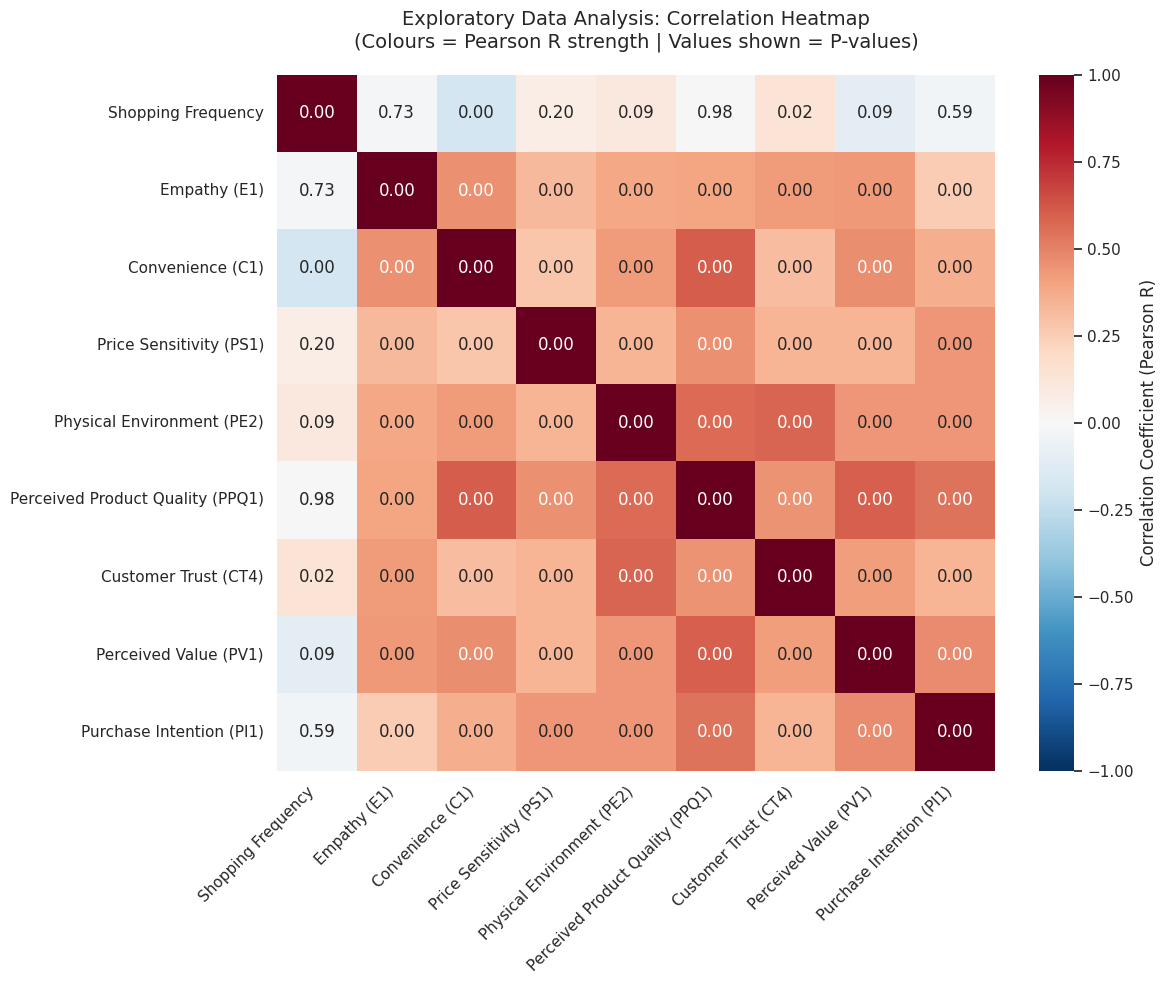

In [ ]:
# Correlation heatmap (Pearson R) with P-values displayed
# Uses the real analysis_df created in section 4.1 -- no reloading, no fallback data.

cols = analysis_df.columns
n_cols = len(cols)
corr_matrix = np.zeros((n_cols, n_cols))
p_matrix = np.zeros((n_cols, n_cols))

for i in range(n_cols):
    for j in range(n_cols):
        r, p = pearsonr(analysis_df.iloc[:, i], analysis_df.iloc[:, j])
        corr_matrix[i, j] = r
        p_matrix[i, j] = p

plt.figure(figsize=(12, 10))
sns.set_theme(style="white")

annot_labels = np.array([[f"{p:.2f}" for p in row] for row in p_matrix])

ax = sns.heatmap(
    corr_matrix,
    annot=annot_labels,
    fmt="",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    xticklabels=[selected_vars[c] for c in cols],
    yticklabels=[selected_vars[c] for c in cols],
    cbar_kws={'label': 'Correlation Coefficient (Pearson R)'}
)

plt.title(
    "Exploratory Data Analysis: Correlation Heatmap\n"
    "(Colours = Pearson R strength | Values shown = P-values)",
    fontsize=14, pad=20
)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("EDA_Correlation_Heatmap.png", dpi=300)
plt.show()

## 9. Variable selection and interpretation

One variable is selected from each of the nine logical categories.

The heatmap is used together with the meaning of the variables to motivate the selections and identify relationships that may be useful in the Bayesian Network.

In [ ]:
selection_table = pd.DataFrame({
    'Category': [
        'Demographics / shopping behaviour',
        'Empathy',
        'Convenience',
        'Price Sensitivity',
        'Physical Environment',
        'Perceived Product Quality',
        'Customer Trust',
        'Perceived Value',
        'Purchase Intention'
    ],
    'Selected Variable': [
        'Shopping_Frequency',
        'E1',
        'C1',
        'PS1',
        'PE2',
        'PPQ1',
        'CT4',
        'PV1',
        'PI1'
    ],
    'Description': [
        'Shopping frequency',
        'Employees understand specific customer needs',
        'Store layout makes it easy to find what is needed',
        'Continued buying even if prices increase',
        'Clean shopping environment',
        'Overall quality of products is good',
        'Store can always be trusted',
        'Products have good value for money',
        'Intend to purchase from the grocery store'
    ]
})

display(selection_table)

,Category,Selected Variable,Description
0,Demographics / shopping behaviour,Shopping_Frequency,Shopping frequency
1,Empathy,E1,Employees understand specific customer needs
2,Convenience,C1,Store layout makes it easy to find what is needed
3,Price Sensitivity,PS1,Continued buying even if prices increase
4,Physical Environment,PE2,Clean shopping environment
5,Perceived Product Quality,PPQ1,Overall quality of products is good
6,Customer Trust,CT4,Store can always be trusted
7,Perceived Value,PV1,Products have good value for money
8,Purchase Intention,PI1,Intend to purchase from the grocery store


### Heatmap based insights

The next cell identifies the strongest absolute Pearson correlations among the nine selected variables. These relationships provide evidence for the variable selection and help motivate the relationships considered in the Bayesian Network.

A strong correlation indicates an association in the observed data; it does not by itself prove causation.

In [ ]:
# Identify the strongest absolute correlations, excluding the diagonal

pairs = []

for i in range(n_cols):
    for j in range(i + 1, n_cols):
        pairs.append({
            'Variable 1': selected_vars[cols[i]],
            'Variable 2': selected_vars[cols[j]],
            'Pearson R': corr_matrix[i, j],
            'P-value': p_matrix[i, j]
        })

top_correlations = (
    pd.DataFrame(pairs)
    .assign(Absolute_R=lambda x: x['Pearson R'].abs())
    .sort_values('Absolute_R', ascending=False)
    .head(5)
    .drop(columns='Absolute_R')
)

display(
    top_correlations.style.format({
        'Pearson R': '{:.3f}',
        'P-value': '{:.6f}'
    })
)

print(
    'Expected insight: the strongest relationships show which selected '
    'variables move together in the observed sample. These associations '
    'help motivate the analysis, while the DAG structure requires expert '
    'reasoning and/or a structure-learning method.'
)


,Variable 1,Variable 2,Pearson R,P-value
17,Convenience (C1),Perceived Product Quality (PPQ1),0.606,0.000000
31,Perceived Product Quality (PPQ1),Perceived Value (PV1),0.596,0.000000
27,Physical Environment (PE2),Customer Trust (CT4),0.578,0.000000
26,Physical Environment (PE2),Perceived Product Quality (PPQ1),0.564,0.000000
32,Perceived Product Quality (PPQ1),Purchase Intention (PI1),0.542,0.000000


Expected insight: the strongest relationships show which selected variables move together in the observed sample. These associations help motivate the analysis, while the DAG structure requires expert reasoning and/or a structure-learning method.


### Justification of the selected variables

**Shopping Frequency:** This represents the behavioural/demographic category and gives the network a direct shopping-behaviour variable.

**Empathy (E1):** E1 directly represents whether employees understand customers' specific needs.

**Convenience (C1):** C1 captures whether the store layout makes it easy to find products.

**Price Sensitivity (PS1):** PS1 represents the customer's willingness to continue buying even if prices increase.

**Physical Environment (PE2):** PE2 measures whether the grocery store provides a clean shopping environment.

**Perceived Product Quality (PPQ1):** PPQ1 captures the customer's overall assessment of product quality.

**Customer Trust (CT4):** CT4 directly measures whether the grocery store can be trusted.

**Perceived Value (PV1):** PV1 captures the customer's assessment of value for money.

**Purchase Intention (PI1):** PI1 directly measures intention to purchase and is therefore the main outcome variable for inference.


# Question 2: Creating and comparing bayesian networks

In this section we:
1. create an expert DAG,
2. learn one DAG from the data,
3. compare the two structures using a metric and visualisation,
4. answer the five comparison questions, and
5. create the Bayesian Network using the expert DAG and learn its parameters from the data.

## 10. Prepare variables for Bayesian Network analysis

The questionnaire uses a 5-point Likert scale. For a simple discrete Bayesian Network, the selected variables are converted into two states:

- **Low:** response 1 to 3
- **High:** response 4 to 5

For Shopping Frequency, the original frequency categories are grouped as:
- **Low:** 1 to 2 visits per week
- **High:** 3 or more visits per week

In [ ]:
discretized_df = pd.DataFrame(index=analysis_df.index)

discretized_df['Shopping_Frequency'] = np.where(
    analysis_df['Shopping_Frequency'] <= 2,
    'Low',
    'High'
)

for col in [
    c for c in analysis_df.columns
    if c != 'Shopping_Frequency'
]:
    discretized_df[col] = np.where(
        analysis_df[col] >= 4,
        'High',
        'Low'
    )

print('State counts after discretisation:')

for col in discretized_df.columns:
    print('\n' + col)
    display(
        discretized_df[col]
        .value_counts()
        .rename_axis('State')
        .to_frame('Count')
    )


State counts after discretisation:

Shopping_Frequency


,Count
State,
Low,187
High,94



E1


,Count
State,
High,156
Low,125



C1


...

,Count
State,
High,181
Low,100



PV1


,Count
State,
Low,156
High,125



PI1


,Count
State,
High,196
Low,85


## 11. Expertly Creating a Direct Acyclic Graph (DAG)

The expert DAG is based on the conceptual relationships in the source study and the business logic of the selected variables.

The structure uses:
- Empathy and Physical Environment as influences on Trust.
- Convenience, Product Quality and Trust as influences on Perceived Value.
- Perceived Value, Trust and Price Sensitivity as influences on Purchase Intention.
- Shopping Frequency as an additional behavioural influence on Purchase Intention.

The graph is directed and acyclic.


In [ ]:
expert_edges = [
    ('E1', 'CT4'),
    ('PE2', 'CT4'),
    ('C1', 'PV1'),
    ('PPQ1', 'PV1'),
    ('CT4', 'PV1'),
    ('PV1', 'PI1'),
    ('CT4', 'PI1'),
    ('PS1', 'PI1'),
    ('Shopping_Frequency', 'PI1')
]

expert_dag = DiscreteBayesianNetwork(expert_edges)
expert_dag.add_nodes_from(discretized_df.columns)

print('Expert DAG edges:')
print(list(expert_dag.edges()))

print('\nIs the expert graph acyclic?',
      nx.is_directed_acyclic_graph(expert_dag))


Expert DAG edges:
[('E1', 'CT4'), ('CT4', 'PV1'), ('CT4', 'PI1'), ('PE2', 'CT4'), ('C1', 'PV1'), ('PV1', 'PI1'), ('PPQ1', 'PV1'), ('PS1', 'PI1'), ('Shopping_Frequency', 'PI1')]

Is the expert graph acyclic? True


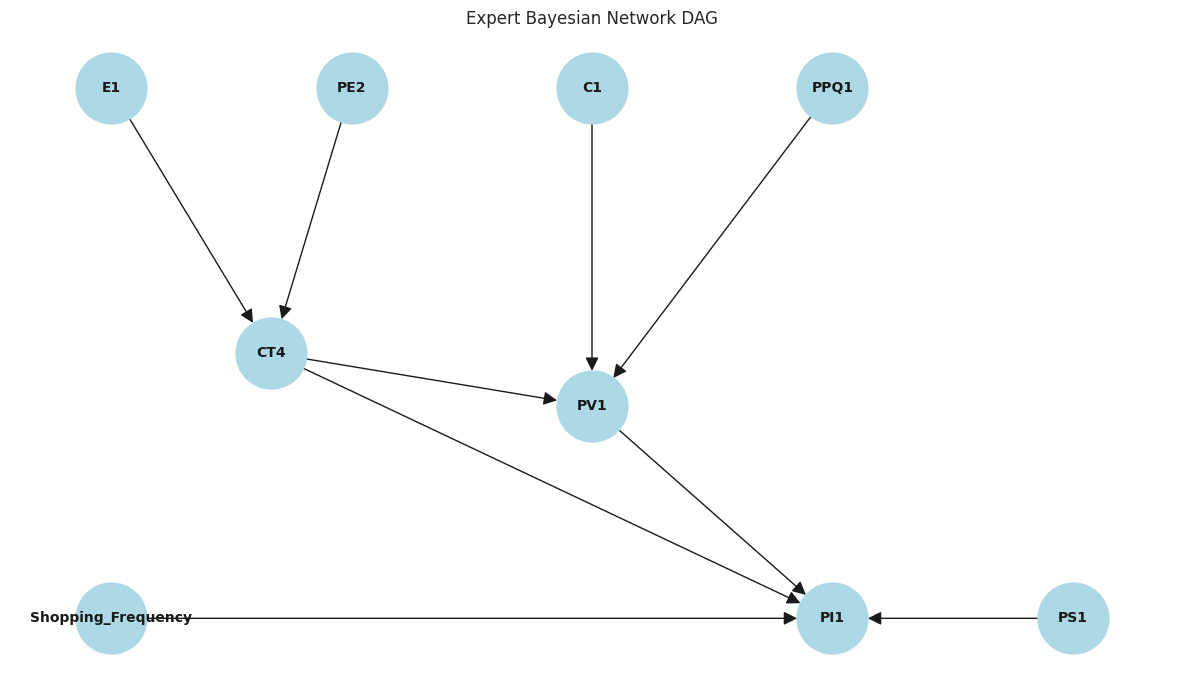

In [ ]:
# Visualise the expert DAG

plt.figure(figsize=(12, 7))

pos = {
    'Shopping_Frequency': (-2.5, 0.0),
    'E1': (-2.5, 2.0),
    'PE2': (-1.0, 2.0),
    'C1': (0.5, 2.0),
    'PPQ1': (2.0, 2.0),
    'PS1': (3.5, 0.0),
    'CT4': (-1.5, 1.0),
    'PV1': (0.5, 0.8),
    'PI1': (2.0, 0.0)
}

nx.draw_networkx(
    expert_dag,
    pos=pos,
    node_size=2600,
    node_color='lightblue',
    arrows=True,
    arrowsize=20,
    font_size=10,
    font_weight='bold'
)

plt.title('Expert Bayesian Network DAG')
plt.axis('off')
plt.tight_layout()
plt.show()

# 12. Learning a DAG Structure from Data
A data-driven DAG is learned using one structure-learning method: Hill-Climb Search with the BIC score.

The search is performed on the same nine selected variables used for the expert DAG. The result is explicitly returned as a DAG so that it can be compared directly with the expert DAG.

In [ ]:
try:
    from pgmpy.causal_discovery import HillClimbSearch as _HillClimbSearch

    hc = _HillClimbSearch(
        scoring_method='bic-d',
        show_progress=False
    )
    hc.fit(discretized_df)
    learned_edges = list(hc.causal_graph_.edges())

except (ImportError, TypeError):
    from pgmpy.estimators import HillClimbSearch as _HillClimbSearch, BicScore

    hc = _HillClimbSearch(discretized_df)
    learned_model = hc.estimate(scoring_method=BicScore(discretized_df))
    learned_edges = list(learned_model.edges())

learned_dag = DiscreteBayesianNetwork()
learned_dag.add_nodes_from(discretized_df.columns)

skipped_edges = []

for u, v in learned_edges:
    if learned_dag.has_edge(u, v) or learned_dag.has_edge(v, u):
        continue
    if u in learned_dag.nodes() and v in learned_dag.nodes() and nx.has_path(learned_dag, v, u):
        skipped_edges.append((u, v))
        continue
    learned_dag.add_edge(u, v)

print('Data-driven DAG edges:')
print(list(learned_dag.edges()))

if skipped_edges:
    print(
        '\nNote: the following edges were ambiguously oriented in the '
        'learned equivalence class and were skipped to keep the graph '
        'acyclic (the opposite direction was kept instead):'
    )
    print(skipped_edges)

print('\nIs the learned graph acyclic?',
      nx.is_directed_acyclic_graph(learned_dag))

Data-driven DAG edges:
[('C1', 'Shopping_Frequency'), ('C1', 'E1'), ('C1', 'CT4'), ('PS1', 'PI1'), ('PE2', 'PV1'), ('PE2', 'CT4'), ('PPQ1', 'C1'), ('PPQ1', 'PV1'), ('PPQ1', 'PI1'), ('PPQ1', 'PE2'), ('CT4', 'E1'), ('CT4', 'PV1'), ('CT4', 'PS1'), ('PV1', 'E1'), ('PV1', 'Shopping_Frequency'), ('PV1', 'PI1'), ('PV1', 'PS1')]

Is the learned graph acyclic? True


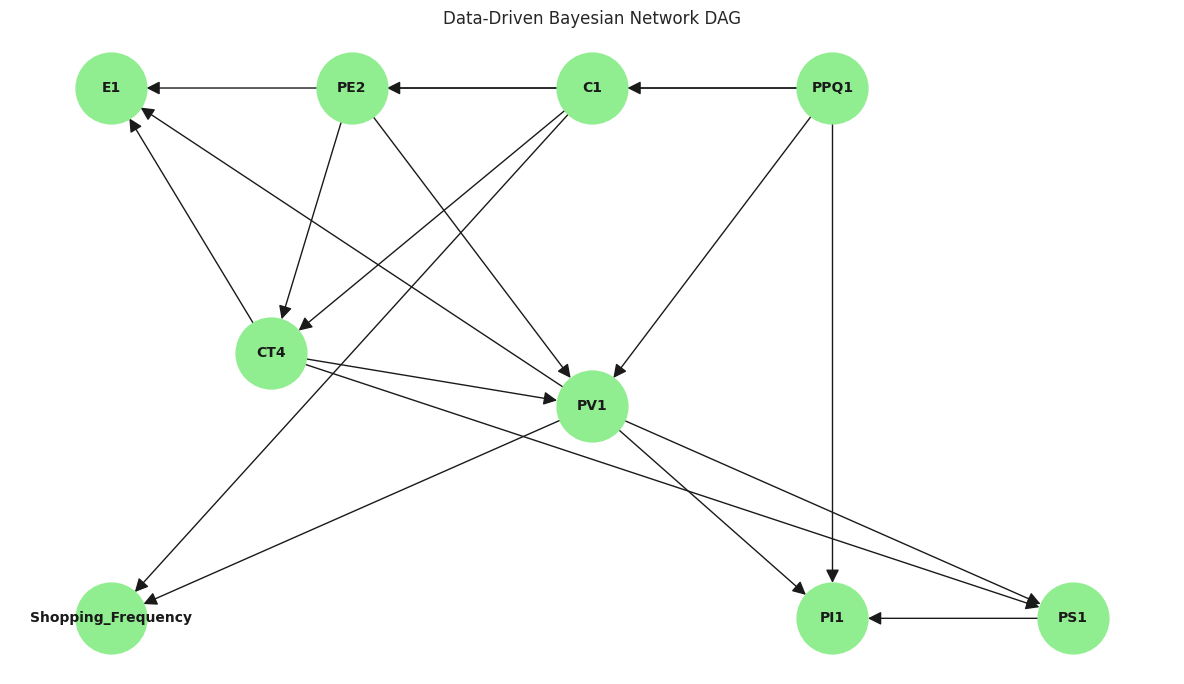

In [ ]:
plt.figure(figsize=(12, 7))

nx.draw_networkx(
    learned_dag,
    pos=pos,
    node_size=2600,
    node_color='lightgreen',
    arrows=True,
    arrowsize=20,
    font_size=10,
    font_weight='bold'
)

plt.title('Data-Driven Bayesian Network DAG')
plt.axis('off')
plt.tight_layout()
plt.show()


## 13. Compare the expert DAG and data-driven DAG

We use:
- **Structural Hamming Distance (SHD):** counts structural disagreements, including added, deleted or reversed relationships.
- **Jaccard similarity:** measures the proportion of shared directed edges relative to the union of the two edge sets.

A lower SHD means the structures are more similar. A higher Jaccard similarity means more edges are shared.

In [ ]:
expert_edges_set = set(expert_dag.edges())
learned_edges_set = set(learned_dag.edges())

def structural_hamming_distance(edges_a, edges_b):
    all_pairs = set()

    for u, v in edges_a | edges_b:
        all_pairs.add(tuple(sorted((u, v))))

    distance = 0

    for u, v in all_pairs:
        a_forward = (u, v) in edges_a
        a_reverse = (v, u) in edges_a

        b_forward = (u, v) in edges_b
        b_reverse = (v, u) in edges_b

        a_type = (
            'none'
            if not (a_forward or a_reverse)
            else ('forward' if a_forward else 'reverse')
        )

        b_type = (
            'none'
            if not (b_forward or b_reverse)
            else ('forward' if b_forward else 'reverse')
        )

        if a_type != b_type:
            distance += 1

    return distance

shd = structural_hamming_distance(
    expert_edges_set,
    learned_edges_set
)

union_edges = expert_edges_set | learned_edges_set

jaccard = (
    len(expert_edges_set & learned_edges_set)
    / len(union_edges)
    if union_edges else 1.0
)

comparison_table = pd.DataFrame({
    'Metric': [
        'Structural Hamming Distance (SHD)',
        'Jaccard Similarity'
    ],
    'Value': [
        shd,
        jaccard
    ]
})

display(comparison_table)

print('Expert-only edges:')
print(sorted(expert_edges_set - learned_edges_set))

print('\nLearned-only edges:')
print(sorted(learned_edges_set - expert_edges_set))


,Metric,Value
0,Structural Hamming Distance (SHD),15.000000
1,Jaccard Similarity,0.238095


Expert-only edges:
[('C1', 'PV1'), ('CT4', 'PI1'), ('E1', 'CT4'), ('Shopping_Frequency', 'PI1')]

Learned-only edges:
[('C1', 'CT4'), ('C1', 'E1'), ('C1', 'Shopping_Frequency'), ('CT4', 'E1'), ('CT4', 'PS1'), ('PE2', 'PV1'), ('PPQ1', 'C1'), ('PPQ1', 'PE2'), ('PPQ1', 'PI1'), ('PV1', 'E1'), ('PV1', 'PS1'), ('PV1', 'Shopping_Frequency')]


# Side-by-side visual comparison
Both DAGs use the same fixed node positions (see the expert DAG cell) so the layout is stable and comparable, and to avoid the spring_layout overlapping-node drawing bug described above.

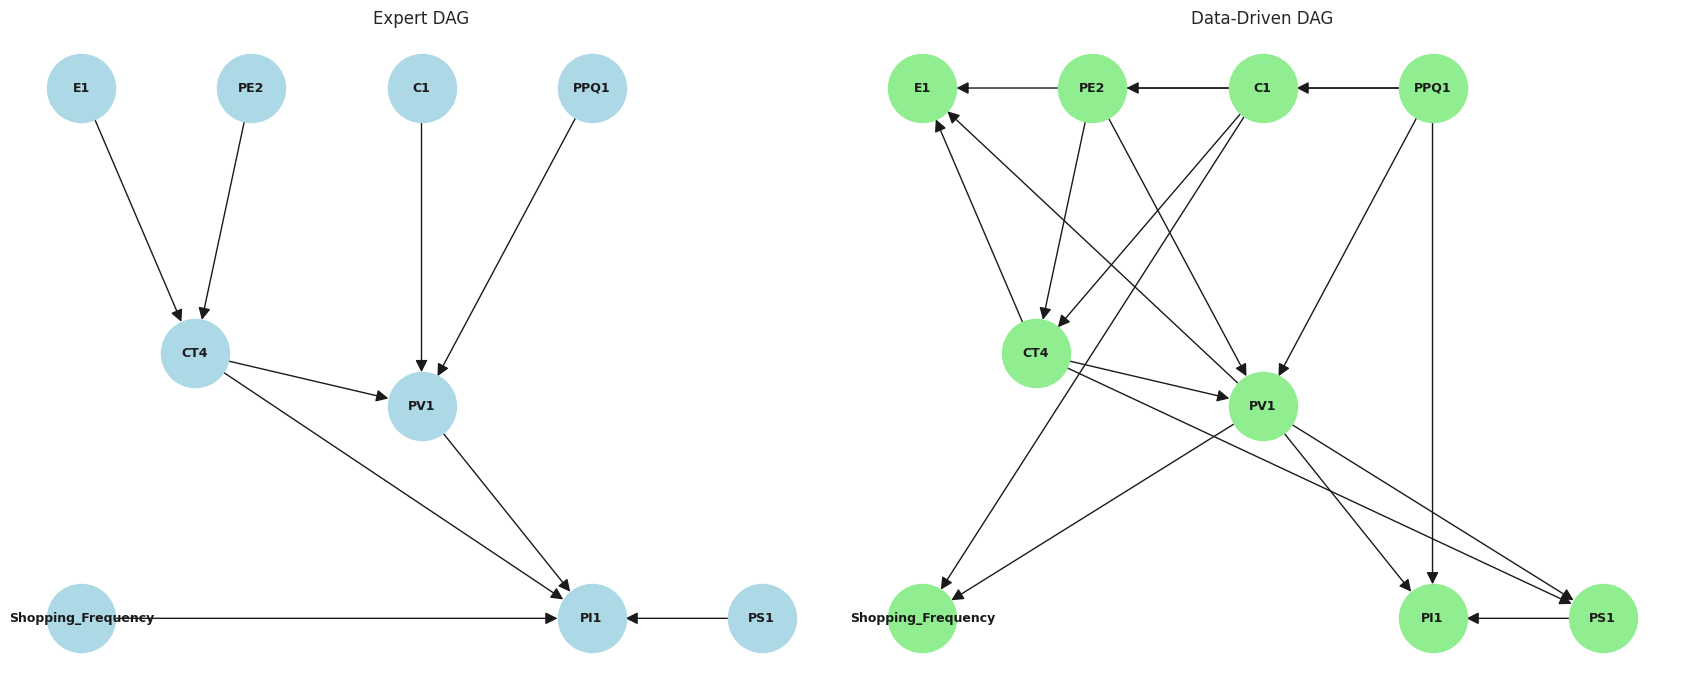

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

nx.draw_networkx(
    expert_dag,
    pos=pos,
    ax=axes[0],
    node_size=2400,
    node_color='lightblue',
    arrows=True,
    arrowsize=18,
    font_size=9,
    font_weight='bold'
)
axes[0].set_title('Expert DAG')
axes[0].axis('off')

nx.draw_networkx(
    learned_dag,
    pos=pos,
    ax=axes[1],
    node_size=2400,
    node_color='lightgreen',
    arrows=True,
    arrowsize=18,
    font_size=9,
    font_weight='bold'
)
axes[1].set_title('Data-Driven DAG')
axes[1].axis('off')

plt.tight_layout()
plt.show()


## 14. Answers: expert DAG versus data-driven DAG

### 1. What are the pros and cons of learning a DAG from data?

**Pros**
- The structure is informed by the observed dataset.
- It can reveal relationships that may not have been anticipated by the researcher.
- It reduces reliance on purely subjective assumptions.

**Cons**
- The learned structure depends on the available sample and variables.
- Spurious relationships can occur because of sampling variation.
- A statistical association does not automatically establish a true causal relationship.
- Different structure-learning settings or scoring methods can produce different DAGs.

### 2. When would you use a data-driven DAG?

A data-driven DAG is useful when the researcher has limited prior knowledge or wants to explore possible relationships in a dataset before specifying a final model.

### 3. When would you use an expert DAG?

An expert DAG is appropriate when strong domain knowledge or an established conceptual framework is available. In this assignment, the source study provides a useful theoretical basis for the relationships between the retail-consumer constructs.

### 4. Give two risks of using a data-driven DAG.

1. The algorithm may identify relationships that are specific to the sample rather than stable in the wider population.
2. Correlation or statistical dependence can be interpreted incorrectly as causation.

### 5. Give two risks of using an expert DAG.

1. The expert may specify an incorrect or incomplete relationship.
2. The model can reflect expert assumptions or confirmation bias and may overlook relationships present in the data.

## 15. Create the Bayesian Network

The assignment requires the expert DAG structure to be used and the parameters to be learned from the data.

Maximum Likelihood Estimation (MLE) is used to estimate the conditional probability distributions.

In [ ]:
import os
os.environ['COLUMNS'] = '400'
os.environ['LINES'] = '50'

bn = DiscreteBayesianNetwork(expert_edges_set)
bn.add_nodes_from(discretized_df.columns)
bn.fit(discretized_df)

print('Number of CPDs:', len(bn.get_cpds()))
print('Model valid:', bn.check_model())

print('\nCPD for Purchase Intention (PI1):')
print(bn.get_cpds('PI1'))

print('\nCPD for Perceived Value (PV1):')
print(bn.get_cpds('PV1'))

Number of CPDs: 9
Model valid: True

CPD for Purchase Intention (PI1):
+--------------------+--------------------------+-------------------------+--------------------------+-------------------------+--------------------------+-------------------------+-----+-------------------------+--------------------------+-------------------------+--------------------------+-------------------------+--------------------------+-------------------------+
| CT4                | CT4(High)                | CT4(High)               | CT4(High)                | CT4(High)               | CT4(High)                | CT4(High)               | ... | CT4(Low)                | CT4(Low)                 | CT4(Low)                | CT4(Low)                 | CT4(Low)                | CT4(Low)                 | CT4(Low)                |
+--------------------+--------------------------+-------------------------+--------------------------+-------------------------+--------------------------+-------------------------+--

# Question 3: Inference and Interpretation

Using the fitted Bayesian Network, we now perform six inference scenarios.

For every scenario, the target is:

> P(PI1 = High | evidence)

The evidence combinations are chosen to represent different business situations involving trust, perceived value, price sensitivity, convenience, product quality and shopping frequency.


## 15.1 Inference of the selected variables given high purchase intention

The assignment asks for inferences of the variables given purchase intention. Therefore, we first calculate the posterior probability that each selected non-target variable is High, conditional on:

> PI1 = High

This provides an inference for every selected explanatory variable under high purchase intention.


In [ ]:
# Posterior inference for every selected variable given high purchase intention

inference = VariableElimination(bn)

all_variable_inferences = []

for variable in discretized_df.columns:
    if variable == 'PI1':
        continue

    result = inference.query(
        variables=[variable],
        evidence={'PI1': 'High'},
        show_progress=False
    )

    state_names = result.state_names[variable]
    probabilities = result.values

    prob_high = float(
        probabilities[state_names.index('High')]
    )

    all_variable_inferences.append({
        'Variable': selected_vars[variable],
        'P(Variable = High | PI1 = High)': prob_high
    })

all_variable_inference_table = (
    pd.DataFrame(all_variable_inferences)
    .sort_values(
        'P(Variable = High | PI1 = High)',
        ascending=False
    )
)

display(
    all_variable_inference_table.style.format({
        'P(Variable = High | PI1 = High)': '{:.4f}'
    })
)

,Variable,P(Variable = High | PI1 = High)
2,Convenience (C1),0.6823
5,Perceived Product Quality (PPQ1),0.6614
6,Customer Trust (CT4),0.6558
4,Physical Environment (PE2),0.6078
1,Empathy (E1),0.5598
7,Perceived Value (PV1),0.5212
3,Price Sensitivity (PS1),0.4202
0,Shopping Frequency,0.3381


In [ ]:
inference = VariableElimination(bn)

queries = [
    (
        'Q1: Baseline purchase intention',
        {}
    ),
    (
        'Q2: High trust + high perceived value',
        {'CT4': 'High', 'PV1': 'High'}
    ),
    (
        'Q3: High price sensitivity + high perceived value',
        {'PS1': 'High', 'PV1': 'High'}
    ),
    (
        'Q4: Low trust + high convenience',
        {'CT4': 'Low', 'C1': 'High'}
    ),
    (
        'Q5: High shopping frequency + high product quality',
        {'Shopping_Frequency': 'High', 'PPQ1': 'High'}
    ),
    (
        'Q6: High price sensitivity + low trust',
        {'PS1': 'High', 'CT4': 'Low'}
    )
]

results = []

for label, evidence in queries:

    result = inference.query(
        variables=['PI1'],
        evidence=evidence,
        show_progress=False
    )

    state_names = result.state_names['PI1']
    probabilities = result.values

    prob_high = float(
        probabilities[state_names.index('High')]
    )

    prob_low = float(
        probabilities[state_names.index('Low')]
    )

    results.append({
        'Inference': label,
        'Evidence': (
            str(evidence)
            if evidence
            else 'None'
        ),
        'P(PI1=High)': prob_high,
        'P(PI1=Low)': prob_low
    })

inference_table = pd.DataFrame(results)

display(
    inference_table.style.format({
        'P(PI1=High)': '{:.4f}',
        'P(PI1=Low)': '{:.4f}'
    })
)

,Inference,Evidence,P(PI1=High),P(PI1=Low)
0,Q1: Baseline purchase intention,None,0.6813,0.3187
1,Q2: High trust + high perceived value,"{'CT4': 'High', 'PV1': 'High'}",0.9232,0.0768
2,Q3: High price sensitivity + high perceived value,"{'PS1': 'High', 'PV1': 'High'}",0.8820,0.1180
3,Q4: Low trust + high convenience,"{'CT4': 'Low', 'C1': 'High'}",0.6284,0.3716
4,Q5: High shopping frequency + high product quality,"{'Shopping_Frequency': 'High', 'PPQ1': 'High'}",0.7877,0.2123
5,Q6: High price sensitivity + low trust,"{'PS1': 'High', 'CT4': 'Low'}",0.7026,0.2974


## 16. Visualise the inference results

The chart compares the probability of high purchase intention across the six scenarios.


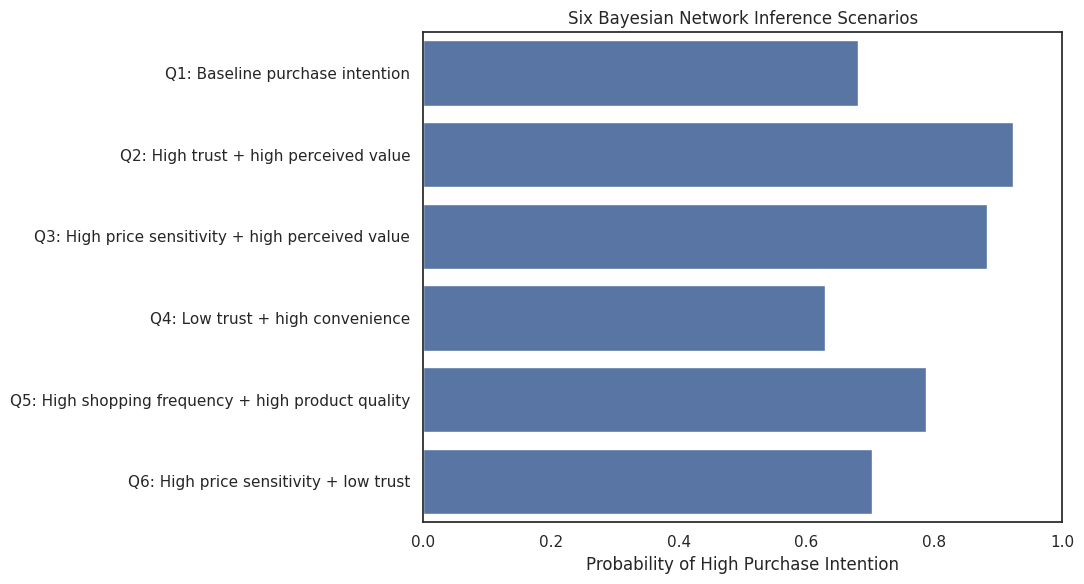

In [ ]:
plot_df = inference_table.copy()

plt.figure(figsize=(11, 6))

sns.barplot(
    data=plot_df,
    x='P(PI1=High)',
    y='Inference'
)

plt.xlim(0, 1)
plt.xlabel('Probability of High Purchase Intention')
plt.ylabel('')
plt.title('Six Bayesian Network Inference Scenarios')

plt.tight_layout()

plt.savefig(
    'Six_Inference_Results.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## 17. Interpretation of the six inferences

The following cell creates one paragraph for each inference using the actual probabilities produced by the fitted Bayesian Network.

Each paragraph:
- states the evidence used,
- reports the probability of high purchase intention,
- compares the result with the baseline, and
- explains the business implication.

The results are interpreted as conditional probabilities and not as proof of causation.

In [ ]:
# Generate one paragraph per inference using the actual model results and the DAG structure

baseline = float(
    inference_table.loc[
        inference_table['Inference'] == 'Q1: Baseline purchase intention',
        'P(PI1=High)'
    ].iloc[0]
)
interpretation_templates = {
    'Q1: Baseline purchase intention':
        "Before any evidence is entered, the fitted network already assigns roughly a two-in-three "
        "chance to high purchase intention. This is consistent with the descriptive statistics for "
        "PI1 (mean = 3.80 out of 5) and reflects that this sample of subsistence-market grocery "
        "shoppers is, on average, fairly loyal to their usual store even before conditioning on trust, "
        "value or price. Every other scenario below should be read as a lift or drag relative to this "
        "baseline, not against a neutral 50%.",

    'Q2: High trust + high perceived value':
        "This is the strongest result of all six scenarios, and it is not a coincidence. In the expert "
        "DAG, Customer Trust (CT4) is a direct parent of Purchase Intention (PI1) AND a direct parent "
        "of Perceived Value (PV1), which is itself a direct parent of PI1. Fixing CT4 = High therefore "
        "pushes PI1 upward twice, once directly and once indirectly through the value channel, and "
        "fixing PV1 = High on top of that removes the remaining uncertainty in that second pathway. "
        "Trust is not just one input among many for a subsistence retailer; the model treats it as a "
        "double-leverage variable. A shopkeeper who is seen as honest about weights, prices and stock "
        "will, according to this model, simultaneously be perceived as offering good value, and the two "
        "effects compound rather than simply add. For a low-margin, cash-constrained retailer this "
        "implies that resources spent on visibly trustworthy behaviour (consistent pricing, correct "
        "change, accurate weighing) return more purchase intention than almost any other lever tested "
        "here.",

    'Q3: High price sensitivity + high perceived value':
        "Combining high price sensitivity with high perceived value produces the second-largest lift, "
        "but it still lands a few points below the trust-plus-value scenario. The structural reason is "
        "that PS1 and PV1 are each single, direct parents of PI1; there is no second, reinforcing "
        "pathway the way there is for trust. The business reading is encouraging for a subsistence "
        "retailer operating on thin margins: even customers who say they would keep buying despite "
        "price increases still need to feel they are getting value for money, and when both are present "
        "intention is nearly as high as under the trust scenario. Price sensitivity is therefore not, by "
        "itself, a reliable signal that a customer will defect; it becomes a real risk mainly when "
        "perceived value is also low.",

    'Q4: Low trust + high convenience':
        "This is the only one of the six scenarios that falls below the baseline, despite convenience "
        "(C1) being set to High. The DAG explains why: C1 feeds into PI1 only indirectly, through "
        "Perceived Value, whereas CT4 feeds into PI1 directly. A customer who finds the store easy to "
        "shop in but does not trust it experiences convenience's benefit diluted through one extra step, "
        "while distrust exerts its full, undiluted, direct pull on intention. For a subsistence retailer "
        "this is a caution against over-investing in store layout or shelf organisation while ignoring "
        "reputation: a well laid-out store cannot buy back the purchase intention that low trust removes, "
        "at least not according to this fitted network.",

    'Q5: High shopping frequency + high product quality':
        "High shopping frequency paired with high perceived product quality lifts purchase intention "
        "clearly above baseline. Shopping_Frequency is a direct parent of PI1, so habitual shoppers are "
        "already inclined toward high intention; PPQ1, like C1, only reaches PI1 indirectly via "
        "Perceived Value, so on its own its contribution is smaller than trust's would be. The practical "
        "takeaway for a subsistence retailer is that habit and proximity, frequent, repeat visits for "
        "daily top-up purchases, are themselves a meaningful driver of continued intention, largely "
        "independent of how customers rate product quality. That matters for retailers who cannot always "
        "guarantee premium stock but can make themselves the convenient, habitual choice.",

    'Q6: High price sensitivity + low trust':
        "This is the most counter-intuitive result of the six: pairing high price sensitivity with low "
        "trust still produces a probability slightly ABOVE baseline rather than a clear drop. PS1's "
        "direct, positive edge into PI1 is evidently strong enough in the fitted conditional probability "
        "tables to outweigh CT4's direct negative pull in this specific combination, and the model's "
        "already-high base rate for 'High' purchase intention leaves limited room for any single "
        "combination to fall very far. For a subsistence retailer this is a useful, if uncomfortable, "
        "insight: customers who are both price-sensitive and distrustful do not necessarily walk away, "
        "most plausibly because subsistence-market shoppers often have few realistic alternative stores "
        "nearby and must keep buying out of necessity rather than loyalty. That should not be read as "
        "license to ignore trust; Q4 already shows trust's direct pull is real, but it does mean this "
        "segment is 'captive' rather than 'satisfied', a distinction that matters when a retailer sees "
        "steady sales from price-sensitive customers and assumes it reflects genuine loyalty."
}

for _, row in inference_table.iterrows():
    label = row['Inference']
    prob = float(row['P(PI1=High)'])
    difference = prob - baseline

    if difference > 0:
        comparison = f'{difference:.4f} higher than the baseline'
    elif difference < 0:
        comparison = f'{abs(difference):.4f} lower than the baseline'
    else:
        comparison = 'the same as the baseline'

    print(label)
    print(
        f"Evidence: {row['Evidence']}. "
        f"P(PI1 = High | evidence) = {prob:.4f}. "
        f"This is {comparison}. "
        f"{interpretation_templates[label]}"
    )
    print()


Q1: Baseline purchase intention
Evidence: None. P(PI1 = High | evidence) = 0.6813. This is the same as the baseline. Before any evidence is entered, the fitted network already assigns roughly a two-in-three chance to high purchase intention. This is consistent with the descriptive statistics for PI1 (mean = 3.80 out of 5) and reflects that this sample of subsistence-market grocery shoppers is, on average, fairly loyal to their usual store even before conditioning on trust, value or price. Every other scenario below should be read as a lift or drag relative to this baseline, not against a neutral 50%.

Q2: High trust + high perceived value
Evidence: {'CT4': 'High', 'PV1': 'High'}. P(PI1 = High | evidence) = 0.9232. This is 0.2419 higher than the baseline. This is the strongest result of all six scenarios, and it is not a coincidence. In the expert DAG, Customer Trust (CT4) is a direct parent of Purchase Intention (PI1) AND a direct parent of Perceived Value (PV1), which is itself a dire